In [18]:
# Load the saved training split and disease names into this notebook.
# Import the tools needed to open and display images.

import csv
import json
from pathlib import Path
from PIL import Image
from IPython.display import display

data_dir = Path("data")
split_dir = Path("splits")

with (split_dir / "train.csv").open(newline="") as file:
    train_records = list(csv.DictReader(file))

with (split_dir / "training_config.json").open() as file:
    training_config = json.load(file)

disease_names = training_config["label_to_disease"]

print("Training images loaded:", len(train_records))

Training images loaded: 14978


Dataset label: Healthy
Original dimensions: (800, 600)
Resized dimensions: (256, 256)


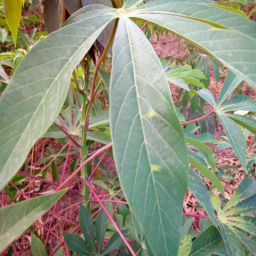

In [19]:
# Preview a training image resized to our hybrid model's 256 × 256 input size.

sample = train_records[0]
image_path = data_dir / "train_images" / sample["image_id"]

with Image.open(image_path) as img:
    original = img.convert("RGB")
    resized = original.resize(
        (256, 256),
        resample=Image.Resampling.BILINEAR
    )

    print("Dataset label:", disease_names[sample["label"]])
    print("Original dimensions:", original.size)
    print("Resized dimensions:", resized.size)
    display(resized)

In [20]:
# Load RGB images at our model's 256 × 256 input size and check 8 images.
# Keep raw 0–255 pixels; normalization happens inside the hybrid model.

import numpy as np

def load_and_resize(filename):
    path = data_dir / "train_images" / filename

    with Image.open(path) as img:
        img = img.convert("RGB")
        img = img.resize(
            (256, 256),
            resample=Image.Resampling.BILINEAR
        )
        return np.array(img, dtype=np.uint8)

sample_records = train_records[:8]

image_batch = np.stack([
    load_and_resize(row["image_id"])
    for row in sample_records
])

label_batch = np.array([
    int(row["label"]) for row in sample_records
])

print("Image batch shape:", image_batch.shape)
print("Image data type:", image_batch.dtype)
print("Pixel range:", image_batch.min(), "to", image_batch.max())
print("Labels:", label_batch)

Image batch shape: (8, 256, 256, 3)
Image data type: uint8
Pixel range: 0 to 255
Labels: [4 0 3 4 2 4 2 3]


Original — Healthy


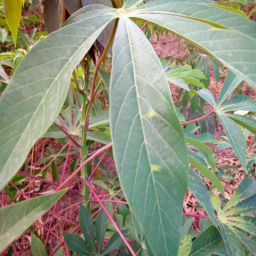

Horizontally flipped — same label


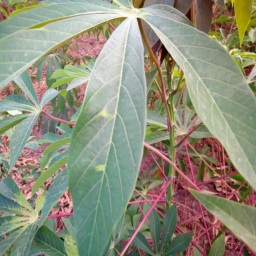

In [21]:
# Preview a horizontal flip of one training image.
# This changes only the in-memory preview, not the saved dataset.

from PIL import ImageOps

example = Image.fromarray(image_batch[0])
flipped = ImageOps.mirror(example)

print("Original —", disease_names[str(label_batch[0])])
display(example)

print("Horizontally flipped — same label")
display(flipped)

In [22]:
# Prepare an image with an optional random horizontal flip for training.
# Keep raw pixels; normalization happens inside the hybrid model.

import random

augmentation_rng = random.Random(42)

def prepare_image(filename, training=False):
    image_array = load_and_resize(filename)

    if training and augmentation_rng.random() < 0.5:
        image_array = np.flip(image_array, axis=1).copy()

    return image_array

# Check that evaluation preprocessing gives repeatable results.
filename = train_records[0]["image_id"]

first = prepare_image(filename, training=False)
second = prepare_image(filename, training=False)

assert np.array_equal(first, second)
assert first.shape == (256, 256, 3)

print("Checks passed: evaluation preprocessing is repeatable.")
print("Training images have a 50% chance of being flipped.")

Checks passed: evaluation preprocessing is repeatable.
Training images have a 50% chance of being flipped.


In [23]:
# Record our preprocessing choices for reproducibility.
# Normalization is handled inside the hybrid model, separately for each branch.

preprocessing_config = {
    "colour_mode": "RGB",
    "image_size": [256, 256],
    "resize_method": "direct_resize",
    "interpolation": "bilinear",
    "output_dtype": "uint8",
    "pixel_range": [0, 255],
    "training_horizontal_flip_probability": 0.5,
    "augmentation_seed": 42,
    "validation_test_random_augmentation": False,
    "normalization": "handled_inside_hybrid_model_per_branch",
}

config_path = split_dir / "preprocessing_config.json"

with config_path.open("w") as file:
    json.dump(preprocessing_config, file, indent=2)

print("Saved:", config_path)

Saved: splits/preprocessing_config.json
